# Лабораторна робота 11: ШІ та хмарні сервіси

**Автор:** Щесняк А. | **Група:** ПІ-25-01 | **Варіант:** 24

In [31]:
# Перший notebook: перевірка середовища Colab
import sys, platform
student = "Щесняк А."
group = "ПІ-25-01"
print("Лабораторна робота 11: ШІ та хмарні сервіси")
print("Автор:", student, group)
print("Версія Python:", sys.version.split()[0])
print("Платформа:", platform.platform())

Лабораторна робота 11: ШІ та хмарні сервіси
Автор: Щесняк А. ПІ-25-01
Версія Python: 3.13.18
Платформа: Linux-6.6.159+-x86_64-with-glibc2.39


## Завдання 4. Набір даних (варіант 24: датчики IoT-стенда)

**Дані навчальні, синтетичні** (вигадані, без персональних даних). 36 рядків: 4 датчики × 9 годин (з 8:00 до 16:00), 5 стовпців: `sensor`, `temperature`, `humidity`, `hour`, `location`. Три значення навмисно змінено, щоб було що шукати в аналізі (аномалії).

In [32]:
import random
import pandas as pd

rng = random.Random(24)  # фіксований seed: набір відтворюється
locations = {"S01": "Lab_A", "S02": "Lab_A", "S03": "Lab_B", "S04": "Server_room"}
base_temp = {"Lab_A": 22.0, "Lab_B": 21.0, "Server_room": 26.0}
base_hum = {"Lab_A": 45.0, "Lab_B": 50.0, "Server_room": 35.0}

rows = []
for hour in range(8, 17):
    for sensor, place in locations.items():
        temp = base_temp[place] + 0.3 * (hour - 8) + rng.uniform(-0.6, 0.6)
        hum = base_hum[place] - 0.5 * (hour - 8) + rng.uniform(-2, 2)
        rows.append({"sensor": sensor, "temperature": round(temp, 1),
                     "humidity": round(hum, 1), "hour": hour, "location": place})

# навмисні аномалії: збій датчика
rows[5]["temperature"] = 58.0
rows[17]["temperature"] = -12.0
rows[28]["humidity"] = 3.5

df = pd.DataFrame(rows)

**Перевірка даних:** типи значень, відсутність дублікатів і пропусків, діапазони. Мінімум і максимум відрізняються від правдоподібних лише через навмисні аномалії.

In [33]:
print(df.dtypes)
print("Дублікати:", df.duplicated().sum())
print("Пропуски:", df.isna().sum().sum())
print(df[["temperature", "humidity"]].agg(["min", "max"]))

sensor          object
temperature    float64
humidity       float64
hour             int64
location        object
dtype: object
Дублікати: 0
Пропуски: 0
     temperature  humidity
min        -12.0       3.5
max         58.0      51.0


**Перегляд і збереження:** форма таблиці, типи, перші рядки; набір зберігаємо у файл `iot_sensors.csv`.

In [34]:
df.to_csv("iot_sensors.csv", index=False)
print(df.shape)
df.info()
df.head()

(36, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sensor       36 non-null     object 
 1   temperature  36 non-null     float64
 2   humidity     36 non-null     float64
 3   hour         36 non-null     int64  
 4   location     36 non-null     object 
dtypes: float64(2), int64(1), object(2)
memory usage: 1.5+ KB


,sensor,temperature,humidity,hour,location
0,S01,22.3,46.4,8,Lab_A
1,S02,21.6,47.0,8,Lab_A
2,S03,20.6,50.7,8,Lab_B
3,S04,25.5,36.0,8,Server_room
4,S01,21.9,45.3,9,Lab_A


### Читання даних із GitHub

Набір збережено в репозиторії (`data/iot_sensors.csv`). Далі працюємо з даними, прочитаними за прямим (raw) посиланням, тому notebook відтворюється з будь-якого місця.

In [35]:
url = "https://raw.githubusercontent.com/idelzss2/cloud-lab-shchesniak/main/data/iot_sensors.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(36, 5)


,sensor,temperature,humidity,hour,location
0,S01,22.3,46.4,8,Lab_A
1,S02,21.6,47.0,8,Lab_A
2,S03,20.6,50.7,8,Lab_B
3,S04,25.5,36.0,8,Server_room
4,S01,21.9,45.3,9,Lab_A


## Завдання 5. Аналіз даних і діаграма

Спочатку описова статистика за числовими стовпцями.

In [36]:
df.describe()

,temperature,humidity,hour
count,36.000000,36.000000,36.000000
mean,23.986111,41.050000,12.000000
std,8.652172,8.830127,2.618615
min,-12.000000,3.500000,8.000000
25%,22.375000,35.800000,10.000000
50%,23.650000,42.700000,12.000000
75%,25.650000,46.175000,14.000000
max,58.000000,51.000000,16.000000


**Групування (`groupby`):** середні температура й вологість за годинами.

In [37]:
hourly = df.groupby("hour")[["temperature", "humidity"]].mean().round(1)
hourly

,temperature,humidity
hour,,
8,22.5,45.0
9,32.0,43.7
10,23.2,43.8
11,23.8,42.0
12,15.2,42.6
13,24.2,41.1
14,24.8,41.1
15,24.8,30.7
16,25.2,39.4


**Фільтр аномалій.** За джерелом про датчики DHT11 (Adafruit) надійний діапазон: температура 0–50 °C, вологість 20–80 %. Значення поза цими межами вважаємо аномальними.

In [38]:
anomalies = df[(df["temperature"] < 0) | (df["temperature"] > 50) | (df["humidity"] < 20) | (df["humidity"] > 80)]
print("Кількість аномальних записів:", len(anomalies))
anomalies

Кількість аномальних записів: 3


,sensor,temperature,humidity,hour,location
5,S02,58.0,45.6,9,Lab_A
17,S02,-12.0,41.4,12,Lab_A
28,S01,23.8,3.5,15,Lab_A


**Діаграма:** середня температура за годинами (лінійна діаграма показує зміну в часі).

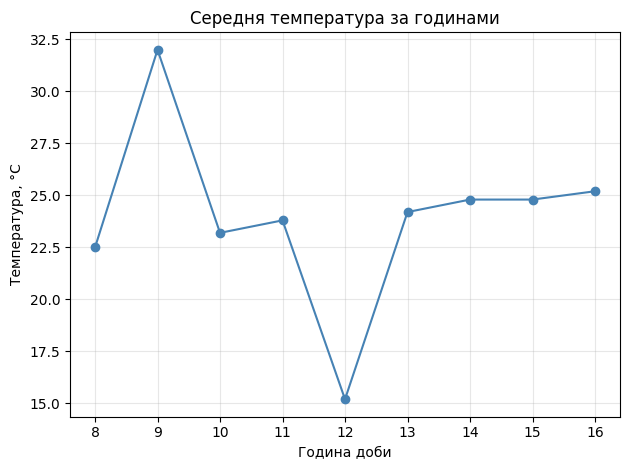

In [39]:
import matplotlib.pyplot as plt
hourly["temperature"].plot(kind="line", marker="o", color="steelblue")
plt.title("Середня температура за годинами")
plt.xlabel("Година доби")
plt.ylabel("Температура, °C")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("chart.png", dpi=150)
plt.show()

## Завдання 6. AI-помічник у кодуванні

**Запит А (генерація).** Gemini попросили порахувати аномальні записи за кожним датчиком і побудувати стовпчикову діаграму. Нижче код, який він запропонував (вставлено й запущено без змін; підсумок збігається з фільтром із завдання 5: 3 аномалії).

sensor
S01    1
S02    2
dtype: int64


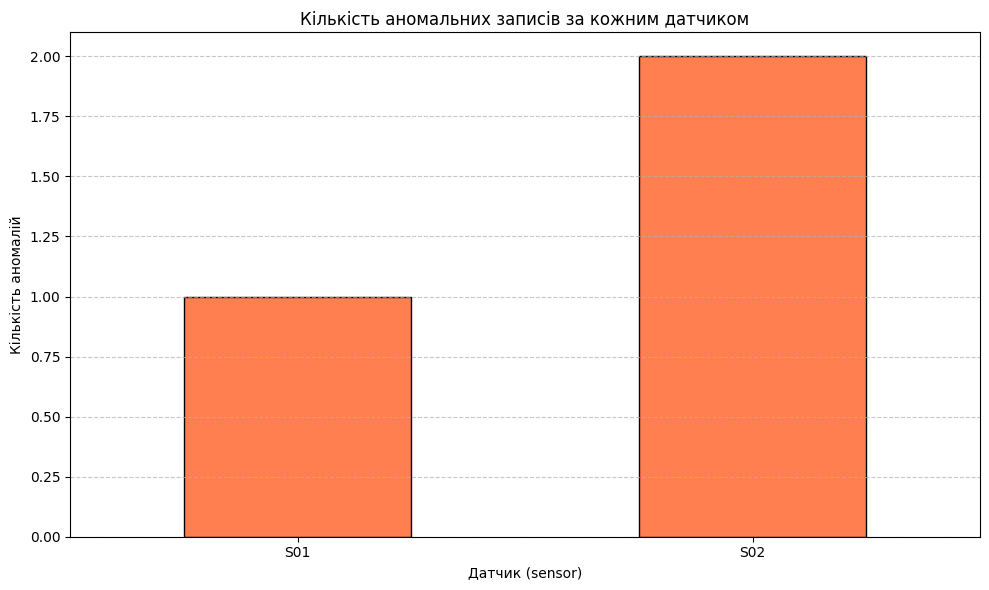

In [40]:
# Код згенеровано Gemini (запит А), запущено без змін
import pandas as pd
import matplotlib.pyplot as plt

# Створюємо булеву маску для виявлення аномалій за заданими умовами
is_anomaly = (
    (df['temperature'] < 0) | (df['temperature'] > 50) |
    (df['humidity'] < 20) | (df['humidity'] > 80)
)

# Підраховуємо кількість аномальних записів для кожного датчика
anomaly_counts = df[is_anomaly].groupby('sensor').size()
print(anomaly_counts)

# Будуємо стовпчикову діаграму
plt.figure(figsize=(10, 6))
anomaly_counts.plot(kind='bar', color='coral', edgecolor='black')

plt.title('Кількість аномальних записів за кожним датчиком')
plt.xlabel('Датчик (sensor)')
plt.ylabel('Кількість аномалій')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Запит Б (виправлення помилки).** Навмисно припустилися друкарської помилки: `df["temperatur"]` замість `df["temperature"]`. Colab показав `KeyError: 'temperatur'`. Це повідомлення разом із потрібним контекстом надіслали Gemini. Він пояснив, що ключа `temperatur` немає (пропущено літеру `e`), і запропонував виправлений рядок. Нижче виправлена комірка; назви стовпців звірено з `df.columns`.

In [41]:
# Виправлення за порадою Gemini (запит Б): правильна назва стовпця
print(df.columns.tolist())
df["temperature"].mean()

['sensor', 'temperature', 'humidity', 'hour', 'location']


np.float64(23.98611111111111)

### Журнал AI

| № | Запит | Що відповів AI | Що змінив я | Як перевірив |
|---|---|---|---|---|
| 1 | «Напиши код на Python (pandas і matplotlib) для Google Colab… підрахуй кількість аномальних записів за кожним датчиком і побудуй стовпчикову діаграму» | Код: булева маска `is_anomaly`, `groupby('sensor').size()`, стовпчикова діаграма із заголовком і підписами осей | Додав `print(anomaly_counts)`, решту залишив без змін | Запустив: S01 = 1, S02 = 2, разом 3. Це збігається з фільтром із завдання 5 (3 аномальні записи) і таблицею аномалій |
| 2 | «Отримав `KeyError: 'temperatur'`… поясни причину й запропонуй виправлення» | Причина: одрук у назві стовпця (немає літери `e`); виправлення `df["temperature"].mean()` | Виправив назву стовпця | Звірив із `df.columns`, комірка виконується без помилки; середнє збігається з `mean` у `df.describe()` (≈ 23,99) |

Власна перевірка: кожен рядок доданого коду зрозумілий. Маска `is_anomaly` поєднує умови через `|`, `df[is_anomaly]` залишає лише аномальні рядки, `groupby('sensor').size()` рахує їх за датчиками, а `plot(kind='bar')` будує діаграму.

## Висновки

1. Набір із 36 записів (4 датчики × 9 годин) не містить дублікатів і пропусків. Три значення аномальні: температура 58,0 °C і −12,0 °C та вологість 3,5 %; усі вони з датчиків S01 і S02 в приміщенні Lab_A.
2. Через ці викиди середня температура за годинами «стрибає»: 32,0 °C о 9:00 і 15,2 °C о 12:00. В інші години вона лежить у межах 22,5–25,2 °C і повільно зростає.
3. Середня вологість у цілому знижується від 45,0 % о 8:00 до 39,4 % о 16:00. Провал до 30,7 % о 15:00 пояснюється одним значенням 3,5 %.
4. Перед аналізом середніх значень аномалії треба відфільтрувати, інакше висновки про динаміку будуть хибними.